# Base Model

In [45]:
import scipy.stats as stats
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import networkx as nx
from collections import defaultdict

class Component:
    def __init__(self, name, maps):
        comp_sys_map, sys_parent_map, parent_bigparent_map, sys_size_map, parent_role_map = maps
        self.name = name
        self.systems = comp_sys_map[name]
        self.parents = sorted(list(set().union(*[sys_parent_map[sys] for sys in self.systems])))
        self.bigparents = sorted(list(set([parent_bigparent_map[parent] for parent in self.parents])))
        self.sizes = sorted(list(set([sys_size_map[sys] for sys in self.systems])))
        self.roles = sorted(list(set().union(*[parent_role_map[parent] for parent in self.parents])))
        self.data = {}
        self.parameters = {}
        self.true_paramters = {
            "mtbf_lambda": np.random.uniform(100, 10000),
            "mttr_lambda": np.random.uniform(80, 8000),
            "spare_rate": np.random.uniform(0.1, 1.25),
            "unit_price": np.random.uniform(100, 10000),
            "important": np.random.choice([True, False], p=[0.8, 0.2])

        }

class System:
    def __init__(self, name, maps):
        self.name = name
        comp_sys_map, sys_parent_map, parent_bigparent_map, sys_size_map, parent_role_map = maps
        self.components = [comp for comp, sys_list in comp_sys_map.items() if name in sys_list]
        self.parents = sorted(list(set(sys_parent_map[name])))
        self.bigparents = sorted(list(set([parent_bigparent_map[parent] for parent in self.parents])))
        self.size = sys_size_map[name]
        self.roles = sorted(list(set().union(*[parent_role_map[parent] for parent in self.parents])))
        self.data = {}
        self.parameters = {}
        self.true_parameters = {
            "say_hio": (np.random.randint(70, 100),np.random.randint(1, 30)),
            "speed": np.random.uniform(1, 8),
            "efficiency": np.random.uniform(0.5, 1.0)
        }

    def create_maintenance_record(self):
        log = []
        while time < 100000:
            part = np.random.choice(self.components)
            time_to_failure = np.random.exponential(part.true_paramters["mtbf_lambda"])
            time_to_repair = np.random.exponential(part.true_paramters["mttr_lambda"])
            log.append([time, time+time_to_failure, time+time_to_failure+time_to_repair, part])
            time += time_to_failure + time_to_repair

class Parent: 
    def __init__(self, name, maps):
        self.name = name
        comp_sys_map, sys_parent_map, parent_bigparent_map, sys_size_map, parent_role_map = maps
        self.components = [comp for comp, sys_list in comp_sys_map.items() if any(sys in sys_list for sys in sys_parent_map if name in sys_parent_map[sys])]
        self.systems = [sys for sys, parent_list in sys_parent_map.items() if name in parent_list]
        self.sizes = sorted(list(set([sys_size_map[sys] for sys in self.systems])))
        self.bigparent = parent_bigparent_map[name]
        self.roles = sorted(list(set(parent_role_map[name])))
        self.data = {}
        self.parameters = {}
        self.true_parameters = None

class BigParent:
    def __init__(self, name, maps):
        self.name = name
        comp_sys_map, sys_parent_map, parent_bigparent_map, sys_size_map, parent_role_map = maps
        self.parents = [parent for parent, bigparent in parent_bigparent_map.items() if bigparent == name]
        self.systems = sorted(list(set([sys for sys, parent_list in sys_parent_map.items() if any(parent in parent_list for parent in self.parents)])))
        self.components = sorted(list(set([comp for comp, sys_list in comp_sys_map.items() if any(sys in sys_list for sys in self.systems)])))
        self.sizes = sorted(list(set([sys_size_map[sys] for sys in self.systems])))
        self.roles = list(set().union(*[parent_role_map[parent] for parent in self.parents]))

        
        

def set_class_objects():
    comp_list = [f"comp_{i}" for i in range(1, 20)]
    sys_list = [f"sys_{i}" for i in range(1, 15)]
    parent_list = [f"parent_{i}" for i in range(1, 10)]
    bigparent_list = [f"bigparent_{i}" for i in range(1, 5)]
    size_list = ["S", "M", "L", "XL"]
    roles = ["Admin", "User", "Guest", "Superuser"]

    np.random.seed(123)
    quant_comp = {comp: np.random.randint(1, 4) for comp in comp_list}
    quant_sys = {sys: np.random.randint(1, 100) for sys in sys_list}
    quant_parent = {parent: np.random.randint(1, 100) for parent in parent_list}

    comp_sys_map = {comp: list(np.random.choice(sys_list, size=np.random.randint(1, 6))) for comp in comp_list}
    sys_parent_map = {sys: list(np.random.choice(parent_list, size=np.random.randint(1, 8))) for sys in sys_list}
    parent_bigparent_map = {parent: np.random.choice(bigparent_list) for parent in parent_list}
    sys_size_map = {sys: np.random.choice(size_list) for sys in sys_list}
    parent_role_map = {parent: list(np.random.choice(roles, size=np.random.randint(1, 5))) for parent in parent_list}
    maps = (comp_sys_map, sys_parent_map, parent_bigparent_map, sys_size_map, parent_role_map)

    comps = {comp:Component(comp, maps) for comp in comp_list}
    syss = {sys: System(sys, maps) for sys in sys_list}
    parents = {parent: Parent(parent, maps) for parent in parent_list}
    bigparents = {bigparent: BigParent(bigparent, maps) for bigparent in bigparent_list}

    return comps, syss, parents, bigparents, comp_sys_map, sys_parent_map, parent_bigparent_map, sys_size_map, parent_role_map







In [46]:

Comps, Sys, Parents, BigParents, comp_sys_map, sys_parent_map, parent_bigparent_map, sys_size_map, parent_role_map = set_class_objects()


In [47]:
def create_edges(Parents, G):
    # Based on the Parent Class
    for parent_i_name in Parents.keys():
        parent_i = Parents[parent_i_name]
        
        # Iterate through each system in parent_i
        for system_name in parent_i.systems:
            system = Sys[system_name]
            
            # Find all parents that have this system
            parents_with_system = sys_parent_map[system_name]
            
            # Check each other parent
            for parent_j_name in parents_with_system:
                if parent_j_name == parent_i_name:
                    continue  # Skip self-loops
                
                parent_j = Parents[parent_j_name]
                
                # Check if they have the same role (at least one role in common)
                common_roles = set(parent_i.roles) & set(parent_j.roles)
                
                if common_roles:
                    # Create edge attributes with system.size and all system.parameters
                    edge_attrs = {
                        "system_name": system_name,
                        "parent_i": parent_i_name,
                        "parent_j": parent_j_name,
                        "system_size": system.size,
                        **system.true_parameters 
                    }
                    
                    # Add edge (using system_name as key for MultiDiGraph to allow multiple edges)
                    G.add_edge(parent_i_name, parent_j_name, key=system_name, **edge_attrs)

    print(f"Added {G.number_of_edges()} edges to the graph")
    print(f"\nExample edge attributes:")
    if G.number_of_edges() > 0:
        first_edge = list(G.edges(keys=True, data=True))[0]
        print(f"Edge {first_edge[0]} -> {first_edge[1]} (system: {first_edge[2]})")
        print(f"Attributes: {first_edge[3]}")
    return G


Added 114 edges to the graph

Example edge attributes:
Edge parent_1 -> parent_9 (system: sys_2)
Attributes: {'system_name': 'sys_2', 'parent_i': 'parent_1', 'parent_j': 'parent_9', 'system_size': 'M', 'say_hio': (86, 27), 'speed': 2.6273584992296506, 'efficiency': 0.6503050677516024}

Example node attributes:
{'roles': ['Guest', 'Superuser', 'User'], 'bigparent': 'bigparent_4', 'systems': ['sys_2', 'sys_4', 'sys_14']}


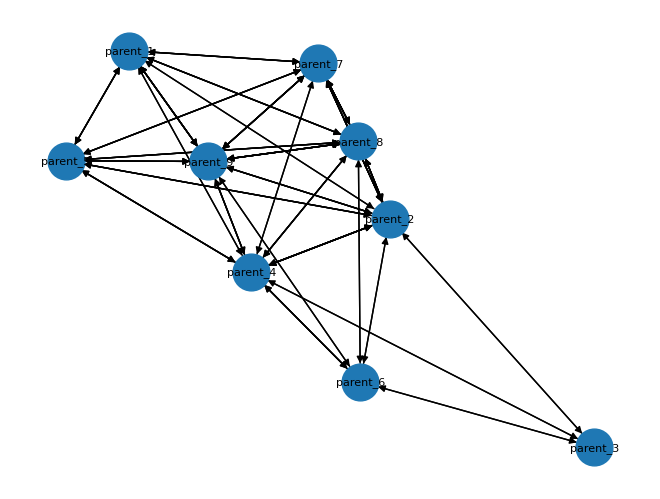

In [48]:
G = nx.MultiDiGraph()
G.add_nodes_from(Parents.keys())
for parent_name, parent_obj in Parents.items():
    G.nodes[parent_name]['roles'] = parent_obj.roles
    G.nodes[parent_name]['bigparent'] = parent_obj.bigparent
    G.nodes[parent_name]['systems'] = parent_obj.systems

G = create_edges(Parents, G)
print(f"\nExample node attributes:\n{list(G.nodes(data=True))[0][1]}")
nx.draw(G, with_labels=True, node_size=700, font_size=8)

In [65]:
def create_traffic(G):
    np.random.seed(123)
    traffic_data = []
    for u, v, key, data in G.edges(keys=True, data=True):
        for n in range(20):
            traffic_data.append({
                "source": u,
                "target": v,
                "system": data["system_name"],
                "size": data["system_size"],
                "speed": np.random.exponential(scale=data["speed"]),
                "arrived": np.random.choice([True, False], p=[data["efficiency"], 1-data["efficiency"]]),
            })
    return pd.DataFrame(traffic_data)

def create_sys_parent_hello(Sys):
    np.random.seed(123)
    hello_data = []
    for sys_obj in Sys.values():
        for parent in sys_obj.parents:
            for i in range(20):
                    hello_data.append({
                        "system": sys_obj.name,
                        "parent": parent,
                        "hello": np.random.beta(*sys_obj.true_parameters["say_hio"])    
                    })
    return pd.DataFrame(hello_data)

tr_df = create_traffic(G)
print(tr_df.head())

hello_df = create_sys_parent_hello(Sys)
print(hello_df.head())

     source    target system size      speed  arrived
0  parent_1  parent_9  sys_2    M   3.132526     True
1  parent_1  parent_9  sys_2    M   0.675978     True
2  parent_1  parent_9  sys_2    M   3.339559     True
3  parent_1  parent_9  sys_2    M  10.380646    False
4  parent_1  parent_9  sys_2    M   1.722812     True
  system    parent     hello
0  sys_1  parent_7  0.746604
1  sys_1  parent_7  0.733437
2  sys_1  parent_7  0.771905
3  sys_1  parent_7  0.791879
4  sys_1  parent_7  0.806904


In [61]:
for sys_obj in Sys.values():
    print(f"System: {sys_obj.name}, Parents: {sys_obj.parents}")

System: sys_1, Parents: ['parent_7']
System: sys_2, Parents: ['parent_1', 'parent_2', 'parent_4', 'parent_5', 'parent_9']
System: sys_3, Parents: ['parent_2', 'parent_4', 'parent_5', 'parent_7', 'parent_8']
System: sys_4, Parents: ['parent_1', 'parent_5', 'parent_7', 'parent_8', 'parent_9']
System: sys_5, Parents: ['parent_9']
System: sys_6, Parents: ['parent_2', 'parent_7', 'parent_9']
System: sys_7, Parents: ['parent_2', 'parent_8']
System: sys_8, Parents: ['parent_8', 'parent_9']
System: sys_9, Parents: ['parent_2', 'parent_4']
System: sys_10, Parents: ['parent_8']
System: sys_11, Parents: ['parent_2', 'parent_3', 'parent_4', 'parent_6']
System: sys_12, Parents: ['parent_2', 'parent_7', 'parent_8']
System: sys_13, Parents: ['parent_4', 'parent_6', 'parent_8', 'parent_9']
System: sys_14, Parents: ['parent_1', 'parent_7', 'parent_8', 'parent_9']


In [50]:
for name, par in Parents.items():
    sub_df = tr_df[tr_df["source"] == name]
    if sub_df.empty:
        continue
    par.data["traffic"] = sub_df
    param1 = par.data["traffic"]["arrived"].value_counts().iloc[0]
    param2 = par.data["traffic"]["arrived"].count() - param1
    par.parameters["traffic_beta_params"] = (param1, param2)
    param_set = stats.weibull_min.fit(par.data["traffic"]["speed"], floc=0)
    par.parameters["traffic_weibull_params"] = param_set

for name, sys in Sys.items():
    sub_df = tr_df[tr_df["system"] == name]
    if sub_df.empty:
        continue
    sys.data["traffic"] = sub_df
    param1 = sys.data["traffic"]["arrived"].value_counts().iloc[0]
    param2 = sys.data["traffic"]["arrived"].count() - param1
    sys.parameters["traffic_beta_params"] = (param1, param2)
    param_set = stats.weibull_min.fit(sys.data["traffic"]["speed"], floc=0)
    sys.parameters["traffic_weibull_params"] = param_set

for u, v, key, data in G.edges(keys=True, data=True):
    sub_df = tr_df[(tr_df["source"] == u) & (tr_df["target"] == v) & (tr_df["system"] == data["system_name"])]
    if sub_df.empty:
        continue
    edge_traffic = sub_df
    param1 = edge_traffic["arrived"].value_counts().iloc[0]
    param2 = edge_traffic["arrived"].count() - param1
    G.edges[u, v, key]["traffic_beta_params"] = (param1, param2)
    param_set = stats.weibull_min.fit(edge_traffic["speed"], floc=0)
    G.edges[u, v, key]["traffic_weibull_params"] = param_set


In [51]:
print(Parents["parent_1"].__dict__)

{'name': 'parent_1', 'components': ['comp_1', 'comp_5', 'comp_7', 'comp_9', 'comp_10', 'comp_12', 'comp_14', 'comp_17', 'comp_18'], 'systems': ['sys_2', 'sys_4', 'sys_14'], 'sizes': ['M', 'S', 'XL'], 'bigparent': 'bigparent_4', 'roles': ['Guest', 'Superuser', 'User'], 'data': {'traffic':        source    target  system size      speed  arrived
0    parent_1  parent_9   sys_2    M   3.132526     True
1    parent_1  parent_9   sys_2    M   0.675978     True
2    parent_1  parent_9   sys_2    M   3.339559     True
3    parent_1  parent_9   sys_2    M  10.380646    False
4    parent_1  parent_9   sys_2    M   1.722812     True
..        ...       ...     ...  ...        ...      ...
215  parent_1  parent_8  sys_14   XL   1.658617     True
216  parent_1  parent_8  sys_14   XL   1.705824     True
217  parent_1  parent_8  sys_14   XL   2.835050     True
218  parent_1  parent_8  sys_14   XL  17.143058     True
219  parent_1  parent_8  sys_14   XL   5.470893     True

[220 rows x 6 columns]}, '

In [52]:
Parents["parent_1"].parameters

{'traffic_beta_params': (140, 80),
 'traffic_weibull_params': (0.9450110806230704, 0, 3.823192235436642)}

NodeDataView({'parent_1': {'roles': ['Guest', 'Superuser', 'User'], 'bigparent': 'bigparent_4', 'systems': ['sys_2', 'sys_4', 'sys_14']}, 'parent_2': {'roles': ['Superuser', 'User'], 'bigparent': 'bigparent_1', 'systems': ['sys_2', 'sys_3', 'sys_6', 'sys_7', 'sys_9', 'sys_11', 'sys_12']}, 'parent_3': {'roles': ['Guest', 'User'], 'bigparent': 'bigparent_1', 'systems': ['sys_11']}, 'parent_4': {'roles': ['Admin', 'Guest', 'User'], 'bigparent': 'bigparent_2', 'systems': ['sys_2', 'sys_3', 'sys_9', 'sys_11', 'sys_13']}, 'parent_5': {'roles': ['Admin', 'User'], 'bigparent': 'bigparent_1', 'systems': ['sys_2', 'sys_3', 'sys_4']}, 'parent_6': {'roles': ['Superuser', 'User'], 'bigparent': 'bigparent_1', 'systems': ['sys_11', 'sys_13']}, 'parent_7': {'roles': ['Superuser', 'User'], 'bigparent': 'bigparent_1', 'systems': ['sys_1', 'sys_3', 'sys_4', 'sys_6', 'sys_12', 'sys_14']}, 'parent_8': {'roles': ['Admin', 'Guest', 'User'], 'bigparent': 'bigparent_2', 'systems': ['sys_3', 'sys_4', 'sys_7', '